# Fenton runaway case after the overshoot-relaxation fix

Case: `Configuration_Bordet_Emballement.toml` (beams `conv`, `UHDR_Emballement`, `UHDR`, `UHDR_Freeze`) with this folder's
`reactions_biology.toml` (catalase = 0, Fe2+ = 2.2e-8 mol/L fixed, no GSH), 50 µmol/L O2, simulated time 1200 s,
`max_step_size_on=1e-4`, `max_step_size_off=0.5`. Both TOML files are used unchanged.

Sections:
1. Recap of the old symptoms
2. 1200 s runs: `UHDR`, `conv`, `UHDR_Freeze` (ROOH, H2O2, Fe3+, solver statistics)
3. Frequency scan 0.10 to 0.16 Hz, with and without Fe2+
4. Map of normalized ROOH at max dose
5. Map of ROOH at the end time

All concentrations are in µmol/L unless stated otherwise.

## 1. Recap of the old symptoms

Before the fix (LSODA stalling near zero concentration), this case showed two symptoms:

- **Freeze**: the run with `UHDR_Freeze` (0.4 Gy/s mean dose rate, 0.13 Hz) froze: LSODA stopped making progress and the simulation never finished.
- **Islands**: the ROOH map (dose per pulse x average dose rate) was full of islands of high and low values, with holes at the points where the solver failed.

Both were solver artifacts, not chemistry. They are fixed by the overshoot relaxation of `derive` (see `ANALYSIS.md` and the CHANGELOG). The old code is not run here.
This notebook runs the current code and shows what is left: the ROOH growth that comes from the chemistry itself.

Two remarks on the files of this folder:

- `Configuration_Bordet_Emballement.toml` includes the packaged `radiopyo/config_Labarbe.toml`, and with it the *packaged* biology (catalase 8e-8 mol/L, GSH 6.5 mmol/L, Fe2+ 8.9e-7 mol/L), which is not the runaway case.
  The helper `fenton_map.load_config` therefore merges the water radiolysis, **this folder's** `reactions_biology.toml` and the beams of the Configuration file, in memory. The folder's biology file also sets `H2O = 55`, which the water radiolysis already defines: that line is dropped in memory, the files are not modified.
- **SOD label**: this folder's `reactions_biology.toml` still writes the superoxide dismutase reaction with the label `O2_r_minus` (`2 O2_r_minus -> H2O2 + O2`), while the water radiolysis names superoxide `O2_minus`. The reaction therefore never acts on the real superoxide (a separate, unused species `O2_r_minus` appears in the species list).
  This was fixed in the packaged file; it is left as is here on purpose. The effect on this case is small (ROOH 2.38 vs 2.40 µmol/L, `ANALYSIS.md` section 5).

In [1]:
import os
os.environ["TQDM_DISABLE"] = "1"      # no progress bars in the saved outputs
import tqdm.notebook, tqdm.std
tqdm.notebook.tqdm = tqdm.std.tqdm     # the widget variant breaks when disabled

import sys, time, logging, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()
sys.path.insert(0, str(HERE))
from fenton_map import compute_map, load_config, ON_TIME, LET, MAX_DOSE   # first: puts the repo checkout on sys.path
import radiopyo as rp
from radiopyo.physics.beam import PulsedBeam

logging.getLogger("radiopyo").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")

PERIOD = 1200.0            # simulated time [s]
FE_CONFIG = 2.2e-8         # Fe2+ of the folder's reactions_biology.toml [mol/L]
RUN_KW = dict(max_step_size_on=1e-4, max_step_size_off=0.5)

# one palette for the whole notebook
COLORS = {"conv": "#3b3b3b", "UHDR": "#d1495b", "UHDR_Emballement": "#edae49", "UHDR_Freeze": "#00798c"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False,
})

def make_cell(fe=None):
    # UnitCell of the Fenton case (fe: Fe2+ in mol/L, None = value of the TOML file)
    return rp.UnitCell.from_config_dict(load_config(fe))

uc = make_cell()
print("Fixed Fe2+ [mol/L]:", FE_CONFIG, "| catalase = 0 | O2(0) = 50 umol/L | simulated time:", PERIOD, "s")

Fixed Fe2+ [mol/L]: 2.2e-08 | catalase = 0 | O2(0) = 50 umol/L | simulated time: 1200.0 s


## 2. 1200 s runs: UHDR, conv, UHDR_Freeze

Each beam of the config file is selected by its label and run for 1200 s. The table gives the solver statistics: every run must finish (no `SolverFailedError`) and all LSODA calls must report success.

In [2]:
def run_label(uc, label, period=PERIOD):
    uc.set_beam(label)
    t0 = time.perf_counter()
    res = uc.prepare_chunked_run([1e-9, period], **RUN_KW).run()
    return res, time.perf_counter() - t0

def stats(label, res, wall):
    df = res.to_pandas()
    return {
        "beam": label,
        "chunks": len(res.success),
        "all chunks OK": all(res.success),
        "points": int(sum(res.n_points)),
        "nfev": int(sum(res.nfev)),
        "njev": int(sum(res.njev)),
        "solver time [s]": round(float(sum(t for t in res.exec_time if t)), 2),
        "wall time [s]": round(wall, 2),
        "ROOH(1200 s) [µmol/L]": round(float(df["ROOH"].iloc[-1]), 3),
        "H2O2(1200 s) [µmol/L]": round(float(df["H2O2"].iloc[-1]), 3),
        "Fe3+(1200 s) [µmol/L]": round(float(df["Fe_plus_plus_plus"].iloc[-1]), 4),
    }

runs, rows = {}, []
for label in ["UHDR", "conv", "UHDR_Freeze"]:
    res, wall = run_label(uc, label)
    runs[label] = res.to_pandas()
    rows.append(stats(label, res, wall))
pd.DataFrame(rows).set_index("beam").T

beam,UHDR,conv,UHDR_Freeze
chunks,10,3750,8
all chunks OK,True,True,True
points,9758,1116416,10550
nfev,15116,2029444,15748
njev,505,56315,674
solver time [s],1.04,160.64,1.1
wall time [s],1.05,304.25,1.12
ROOH(1200 s) [µmol/L],2.402,6.612,3.01
H2O2(1200 s) [µmol/L],1.063,1.018,1.038
Fe3+(1200 s) [µmol/L],0.0284,0.0265,0.0276


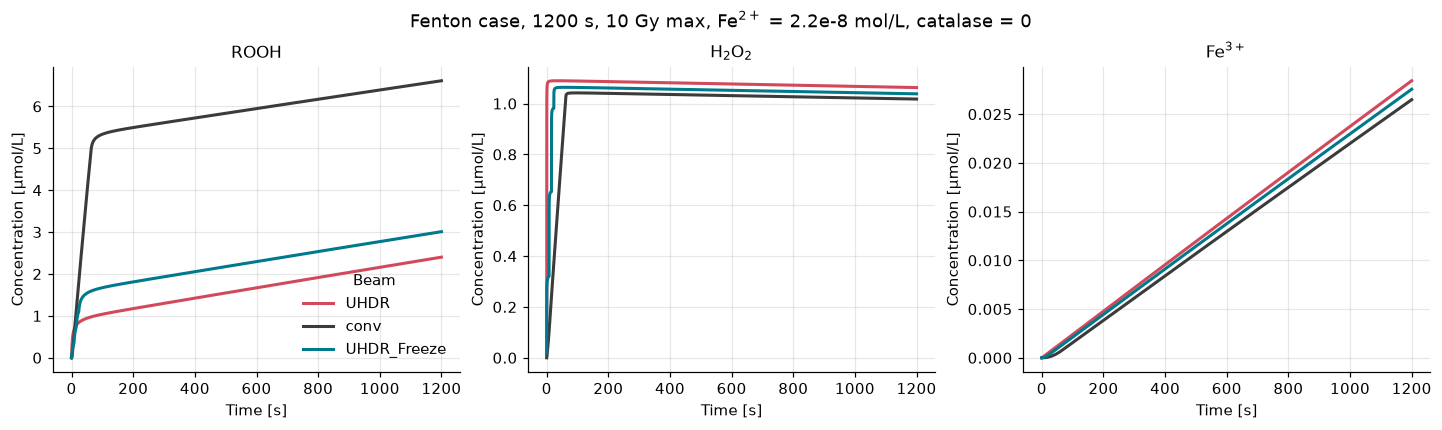

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
for ax, (col, title) in zip(axes, [("ROOH", "ROOH"), ("H2O2", "H$_2$O$_2$"), ("Fe_plus_plus_plus", "Fe$^{3+}$")]):
    for label, df in runs.items():
        ax.plot(df.index, df[col], color=COLORS[label], lw=2, label=label)
    ax.set_title(title)
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
axes[0].legend(title="Beam")
fig.suptitle("Fenton case, 1200 s, 10 Gy max, Fe$^{2+}$ = 2.2e-8 mol/L, catalase = 0", fontsize=12)
plt.show()

What the curves show (see `ANALYSIS.md` sections 2 and 4):

- **H2O2** sits at about 1 µmol/L for the whole run: catalase is 0 in this file, so nothing removes it.
- **Fe3+** accumulates linearly: Fe2+ is a fixed species and is never consumed, and nothing recycles Fe3+.
- **ROOH** keeps growing at a nearly constant rate after the beam stops. The Fenton OH• flux (k x [Fe2+] x [H2O2]) is constant, and the lipid chain `ROO• + RH -> ROOH + R•` regenerates R• with a chain length of about 50.
  The final ROOH therefore depends on when the run stops, not only on the beam. This is chemistry, not a solver artifact.

## 3. Frequency scan around UHDR_Freeze

`UHDR_Freeze` is 0.4 Gy/s (mean dose rate, as `dose_rate` in the TOML beams) at 0.13 Hz. The scan keeps the mean dose rate (0.4 Gy/s), the pulse length (1.2 µs) and the 10 Gy limit, and changes the frequency from 0.10 to 0.16 Hz, with Fe2+ = 0 and Fe2+ = 2.2e-8 mol/L.
Before the fix this range was where LSODA froze. Now every point finishes.

In [4]:
FREQS = np.round(np.arange(0.10, 0.1601, 0.01), 2)
MEAN_DR = 0.4   # Gy/s, mean dose rate (the TOML `dose_rate` of the beams)

def run_freq(cell, freq):
    peak_dr = MEAN_DR / (ON_TIME * freq)      # Gy/s during the pulse
    beam = PulsedBeam.from_dose_rate_peak(peak_dr, 1.0 / freq, ON_TIME, max_dose=MAX_DOSE)
    cell.set_beam(beam, LET=LET)
    return cell.prepare_chunked_run([1e-9, PERIOD], **RUN_KW).run()

scan, n_fail = {}, 0
for fe in (0.0, FE_CONFIG):
    cell = make_cell(fe)
    vals = []
    for f in FREQS:
        res = run_freq(cell, float(f))
        n_fail += not all(res.success)
        vals.append(float(res.to_pandas()["ROOH"].iloc[-1]))
    scan[fe] = vals
tab = pd.DataFrame({"Frequency [Hz]": FREQS,
                    "ROOH(1200 s), Fe2+ = 0 [µmol/L]": np.round(scan[0.0], 3),
                    "ROOH(1200 s), Fe2+ = 2.2e-8 [µmol/L]": np.round(scan[FE_CONFIG], 3)}).set_index("Frequency [Hz]")
print("Runs with a failed chunk:", n_fail)
tab

Runs with a failed chunk: 0


,"ROOH(1200 s), Fe2+ = 0 [µmol/L]","ROOH(1200 s), Fe2+ = 2.2e-8 [µmol/L]"
Frequency [Hz],,
0.10,1.556,2.815
0.11,1.544,2.805
0.12,1.527,2.790
0.13,1.759,3.010
0.14,1.767,3.018
0.15,1.756,3.008
0.16,1.739,2.993


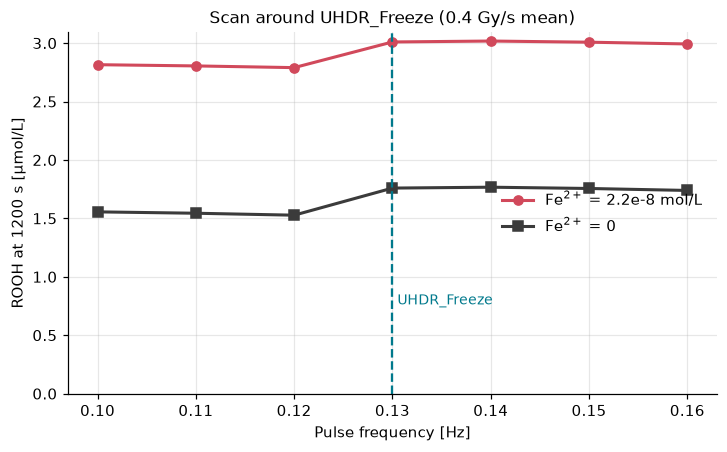

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 4), constrained_layout=True)
ax.plot(FREQS, scan[FE_CONFIG], "o-", color=COLORS["UHDR"], lw=2, label="Fe$^{2+}$ = 2.2e-8 mol/L")
ax.plot(FREQS, scan[0.0], "s-", color=COLORS["conv"], lw=2, label="Fe$^{2+}$ = 0")
ax.axvline(0.13, color=COLORS["UHDR_Freeze"], ls="--", lw=1.5)
ax.text(0.1305, 0.5 * np.min(scan[0.0]), "UHDR_Freeze", color=COLORS["UHDR_Freeze"], fontsize=9)
ax.set_ylim(bottom=0)
ax.set_xlabel("Pulse frequency [Hz]")
ax.set_ylabel("ROOH at 1200 s [µmol/L]")
ax.set_title("Scan around UHDR_Freeze (0.4 Gy/s mean)")
ax.legend(loc="center right")
plt.show()

The curves are smooth: no hole, no freeze. Fenton adds about 1.2 µmol/L on top of the Fe-free value, almost independently of the frequency.
The small step between 0.12 and 0.13 Hz is there without Fe as well, so it does not come from the Fenton reaction.

## 4. Map of normalized ROOH at max dose

Grid of 12 x 12 log-spaced points: dose per pulse 0.03 to 15 Gy, average dose rate 0.2 to 1000 Gy/s, pulse length 1.2 µs, 10 Gy total.
ROOH is read at the end of the last pulse (the time the 10 Gy are reached) and divided by its maximum over the map.
A point is left white (NaN) if it is infeasible (the pulse period would be shorter than the pulse, or the 10 Gy are not delivered within 1200 s) or if its run failed; the cell below prints how many there are.
Each point is a full 1200 s run, computed in parallel by `fenton_map.compute_map` and cached in `.map_cache/`; the cell below loads the cache when it exists.

Map ready in 0.0 s; grid (12, 12) (rows: dose rate, columns: dose per pulse)
Infeasible / failed points: 0 of 144


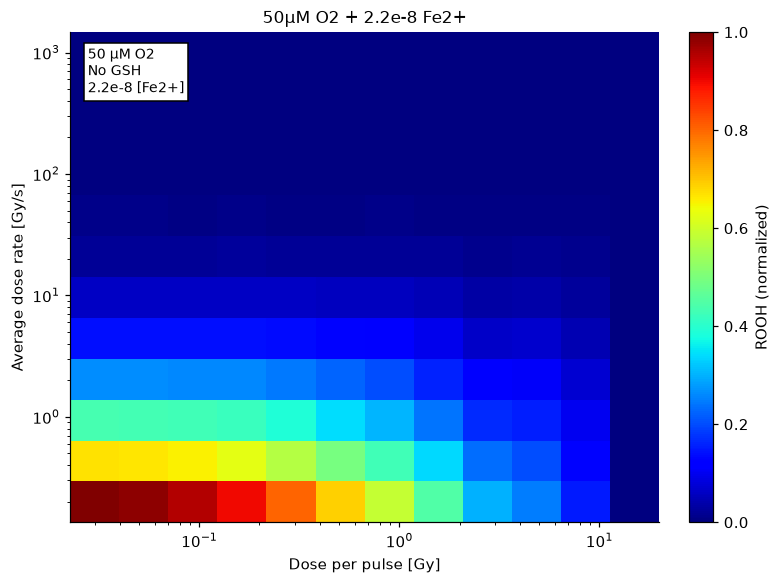

Normalization: ROOH max = 4.366 µmol/L (at max dose)


In [6]:
t0 = time.perf_counter()
fmap = compute_map(n=12, period=PERIOD)
dpp, dr = fmap["dose_per_pulse"], fmap["avg_dose_rate"]
print(f"Map ready in {time.perf_counter() - t0:.1f} s; grid {fmap['rooh_max_dose'].shape} (rows: dose rate, columns: dose per pulse)")
print(f"Infeasible / failed points: {int(np.isnan(fmap['rooh_max_dose']).sum())} of {fmap['rooh_max_dose'].size}")

def edges(x):
    lx = np.log10(x); mid = (lx[1:] + lx[:-1]) / 2
    return 10 ** np.concatenate([[lx[0] - (mid[0] - lx[0])], mid, [lx[-1] + (lx[-1] - mid[-1])]])

def plot_map(z, title, cbar_label, note):
    zn = np.ma.masked_invalid(z / np.nanmax(z))
    cmap = plt.get_cmap("jet").copy(); cmap.set_bad("white")
    fig, ax = plt.subplots(figsize=(7, 5.2), constrained_layout=True)
    m = ax.pcolormesh(edges(dpp), edges(dr), zn, cmap=cmap, vmin=0, vmax=1, shading="flat")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Dose per pulse [Gy]"); ax.set_ylabel("Average dose rate [Gy/s]")
    ax.set_title(title)
    ax.grid(False)
    cb = fig.colorbar(m, ax=ax); cb.set_label(cbar_label)
    ax.text(0.03, 0.97, note, transform=ax.transAxes, va="top", ha="left", fontsize=9,
            bbox=dict(boxstyle="square", facecolor="white", edgecolor="black"))
    return fig, ax

NOTE = "50 µM O2\nNo GSH\n2.2e-8 [Fe2+]"
fig, ax = plot_map(fmap["rooh_max_dose"], "50µM O2 + 2.2e-8 Fe2+", "ROOH (normalized)", NOTE)
plt.show()
print(f"Normalization: ROOH max = {np.nanmax(fmap['rooh_max_dose']):.4g} µmol/L (at max dose)")

The map is smooth, with no island and no hole. ROOH at max dose is mostly set by the *time* needed to deliver the 10 Gy (about 10 / average dose rate): the longer the irradiation lasts, the longer the Fenton chains run before the dose is reached, so the maximum is at low average dose rate.
The last column (15 Gy per pulse, above the 10 Gy limit) is a single pulse, hence a uniform column.

## 5. Map of ROOH at the end time (1200 s)

Same grid and same styling, but ROOH is read at 1200 s and normalized by its maximum.

Reading note: with Fe2+ never consumed and catalase = 0, ROOH drifts linearly after the irradiation (section 2). This map therefore mostly shows that drift, not a radiobiological contrast between beams. See `ANALYSIS.md` sections 2 and 4.

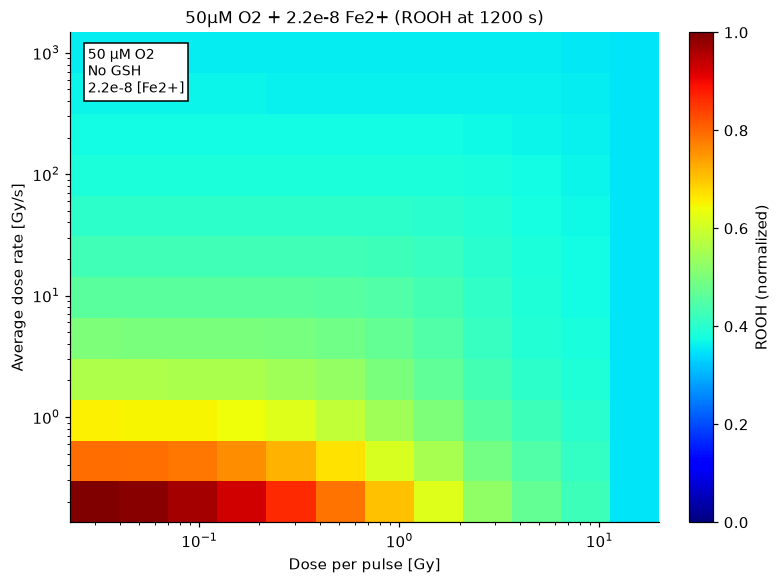

Normalization: ROOH max = 6.119 µmol/L (at 1200 s)


In [7]:
fig, ax = plot_map(fmap["rooh_end"], "50µM O2 + 2.2e-8 Fe2+ (ROOH at 1200 s)", "ROOH (normalized)", NOTE)
plt.show()
print(f"Normalization: ROOH max = {np.nanmax(fmap['rooh_end']):.4g} µmol/L (at 1200 s)")